---
## Trabalho Prático II - Individual
## Data de entrega: 19/09/2024 (Devido a semana integrada)
---

**1- Descrição e Objetivo**

Na área de processamento de imagens, o método conhecido como *chroma key* consiste em substituir o fundo de uma imagem por outro. Uma abordagem comum é utilizar uma imagem com um fundo de cor uniforme, como verde ou azul, e substituir os *pixels* que correspondem a essa cor pela nova imagem. Essa técnica é amplamente empregada na indústria cinematográfica para simplificar a criação de cenários, objetos, personagens e ambientes fictícios. Além disso, o *chroma key* é utilizado na composição de imagens, combinando várias imagens com fundo uniforme para criar uma nova cena. Essa aplicação representa a principal utilização do *chroma key* na produção cinematográfica.

Neste exercício prático, você irá criar uma única imagem combinando várias imagens de entrada. Isso envolve remover o fundo, realizar operações radiométricas e geométricas, além de aplicar filtros, tudo para garantir um resultado final mais satisfatório.

**2- Passo-a-passo da trabalho**

1.   Carregar algumas imagens;
2.   Aplicar a técnica de *chroma key* nas imagens;
3.   Aplicar operações radimétricas, geométricas e de filtros nas imagens;
4.   Combinar todas as imagens em uma só.



In [1]:
import scipy

import matplotlib.pyplot as plt
from random import random
import numpy as np

from skimage import transform as tf
import skimage.io
from skimage.morphology import disk
from skimage.morphology import erosion

import cv2


def open_image(name_file):
    """
    Abre a imagem em modo RGBA

    O cana A (alfa) representa a transparência ou opacidade do pixel.
    Um valor alfa mais alto indica maior opacidade, tornando o pixel mais visível,
    enquanto um valor alfa mais baixo indica maior transparência.

    Retorna:
         Uma matriz numpy que representa a imagem.

    """
    return skimage.io.imread(name_file, mode='RGBA')


def show(img, figsize=(10, 10)):
    """
    Plotar uma imagem
    """
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    ax.imshow(img, cmap=plt.cm.gray)
    ax.set_axis_off()
    plt.show()


def resize_image(img, scale):
    """
    Redimensiona a scale da imagem
    """
    return skimage.transform.resize(img, (int(img.shape[0]*scale/100), int(img.shape[1]*scale/100)), mode='reflect')


# 1- Carregar imagens


(849, 1920, 4)


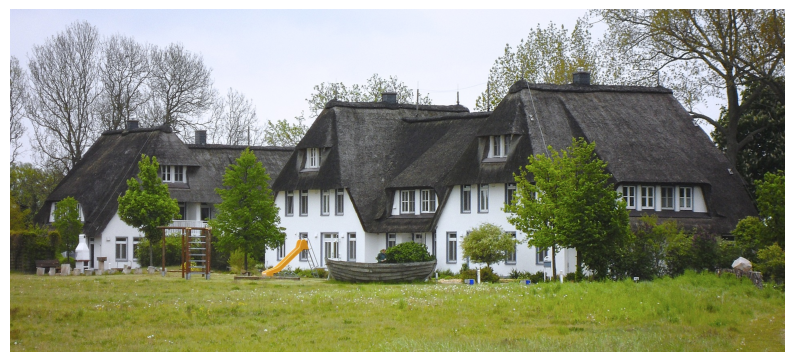

(992, 1908, 4)


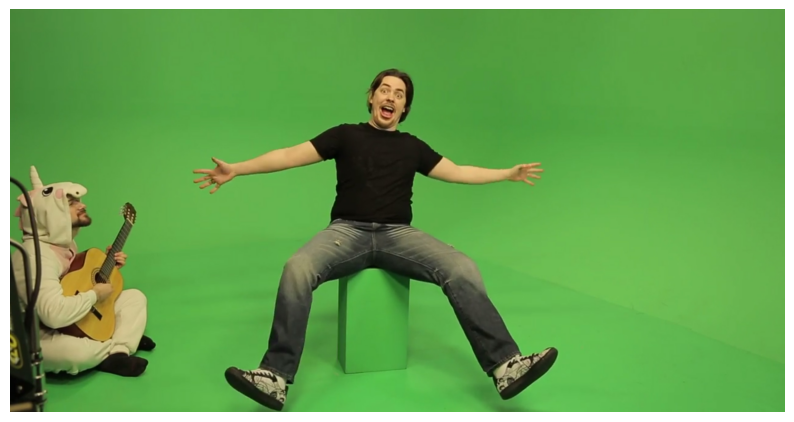

In [2]:
img_background = open_image('./images/background.jpg')
img_chairman = open_image('./images/chairman.jpg')

print(img_background.shape)
show(img_background)
print(img_chairman.shape)
show(img_chairman)


# 2 Aplicar a técnica de *chroma key* em uma imagem

In [3]:
def add_alpha_channel(img):
    rgba = np.concatenate((img[:, :, :3], np.zeros(
        (img.shape[0], img.shape[1], 1), dtype=img.dtype)), axis=2)
    rgba[:, :, 3] = 255  # Valor inteiro para opacidade total, ou seja, transparência 0%

    return rgba


def green_to_transparency(img_in):
    """
    Adiciona transparência em cores verdes através do HSV
    Parâmetros retirados no link
    http://marvinproject.sourceforge.net/en/examples/chromaKey.html
    """
    img = add_alpha_channel(img_in)
    # A imagem RGBA resultante é então convertida para o espaço de cores HSV (matiz, saturação, valor) e excluido o canal alfa.
    hsv = skimage.color.rgb2hsv(img[:, :, :-1])

    width, height = img.shape[:-1]

    # In this step all pixels are processed in the HSV color space. Green pixels are converted
    # to transparent. Given a pixel p, it's is considered "green" if:
    # p.hue >= 60 AND p.hue <= 130 AND p.saturation >= 0.4 AND p.lightness >= 0.3
    hue = hsv[:, :, 0]
    saturation = hsv[:, :, 1]
    lightness = hsv[:, :, 2]
    for x in range(width):
        for y in range(height):
            if 0.25 <= hue[x][y] <= 0.5 and saturation[x][y] >= 0.4 and lightness[x][y] >= 0.2:
                img[x][y] = [0, 0, 0, 0]
    return img


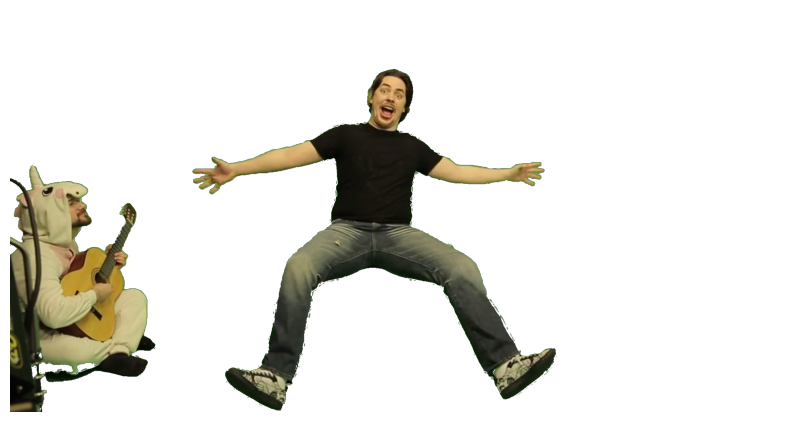

In [4]:
img = green_to_transparency(img_chairman)
show(img)


Note que as bordas ainda possuem vestígios do *chroma key* (verde, é claro).

Portanto, vamos usar a **função alpha_boundary** para realizar uma **erosão** na **camada alfa** e, em seguida, aplicar um **filtro gaussiano** para suavizar as bordas da transparência.

A **erosão** remove pixels de borda, tornando os objetos mais finos e pequenos. É útil a diminuir a intensidade do verde ao redor das bordas.

In [5]:
def alpha_boundary(img, radius=3, sigma=3):
    # Extrai informações do canal alpha - 0 para totalmente transparente, 255 para totalmente opaco.
    alpha_filter = img[:, :, 3]
    """
    A erosão é usada para reduzir a intensidade da transparência ao redor das bordas.
    A aplicação da erosão na matriz alpha_filter permite que somente a transparência da imagem seja afetada.
    Isso preserva as informações de cor e intensidade das outras camadas de cor (R, G, B) da imagem.
    disk(radius) controla o tamanho da área ao redor de cada pixel que será afetada pela erosão.
    Quanto maior o raio, maior será a área ao redor de cada pixel que será considerada na operação de erosão.
    """
    alpha_filter = erosion(alpha_filter, disk(radius))
    """
    Controla a quantidade de suavização aplicada às bordas da transparência. Quanto maior o valor de sigma, mais
    suave será a transição entre os valores dos pixels na imagem.
    cval=0.0 define os pixels da borda fora da imagem para um valor constante de 0,0 (totalmente transparente)
    """
    alpha_filter = skimage.filters.gaussian(
        alpha_filter, sigma=sigma, mode='constant', cval=0.0)

    """
    Imagem resultante em float é convertida de volta para o tipo de dados de 8 bits
    pixel estejam dentro do intervalo correto (0 a 255)
    """
    img[:, :, 3] = skimage.img_as_ubyte(alpha_filter)

    return img


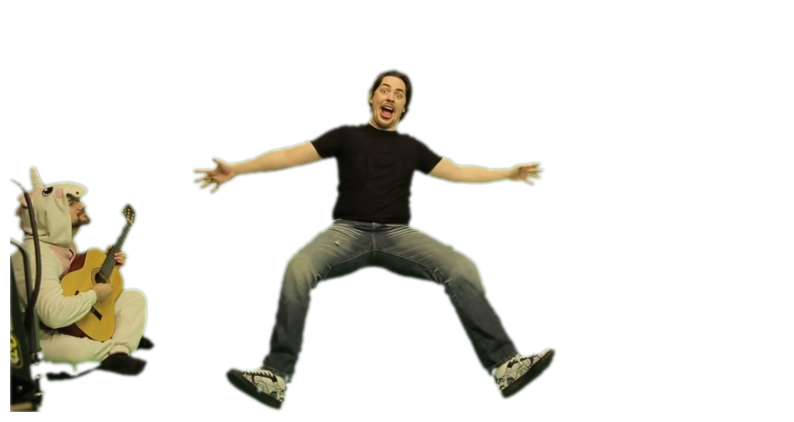

In [6]:
alpha_boundary(img)
show(img)


**Supondo que gostaríamos de retirar o violeiro**

 Desloca a imagem central para a esquerda

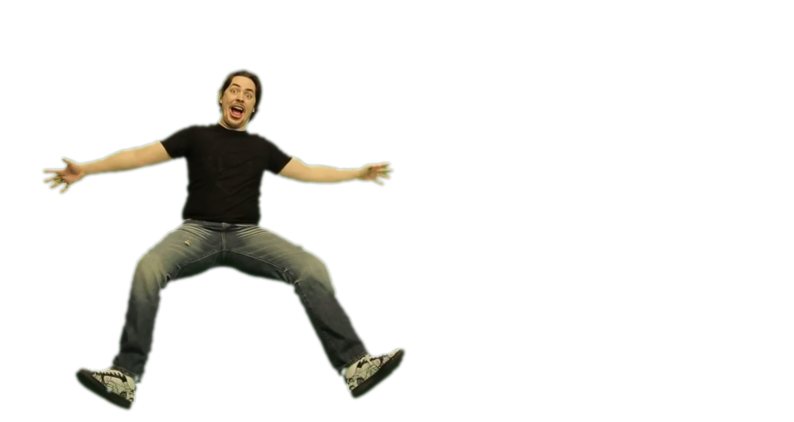

In [7]:
# Os canais da imagem serão deslocados 370 pixels para a esquerda
shift_to_left = -370
"""
O deslocamento é aplicado apenas na direção horizontal (eixo x), mantendo a posição vertical (eixo y) inalterada.
O argumento [0, shift_to_left] 0 indica nenhum deslocamento na direção VERTICAL e o segundo elemento (shift_to_left)
especifica o deslocamento para a esquerda (valor negativo) na direção HORIZONTAL.
O argumento cval=0 especifica o valor de preenchimento para os pixels que se movem para fora dos limites da imagem durante o deslocamento.
"""
shifted_r = scipy.ndimage.shift(img[:, :, 0], [0, shift_to_left], cval=0)
shifted_g = scipy.ndimage.shift(img[:, :, 1], [0, shift_to_left], cval=0)
shifted_b = scipy.ndimage.shift(img[:, :, 2], [0, shift_to_left], cval=0)
shifted_a = scipy.ndimage.shift(img[:, :, 3], [0, shift_to_left], cval=0)
# Isso geralmente é feito para evitar a modificação da imagem original.
shifted = img.copy()
shifted[:, :, 0] = shifted_r
shifted[:, :, 1] = shifted_g
shifted[:, :, 2] = shifted_b
shifted[:, :, 3] = shifted_a
# Substitui a imagem original (img) pela cópia deslocada
img_shifted = shifted
show(img_shifted)


# 3- Combinar todas as imagens em uma única imagem


In [8]:
def insert_image(background, image, position=None):
    """
    Insere uma imagem no background
    position indica onde deve ser inserido (x, y),
    se não for passado é inserido aleatóriamente
    """
    if image.shape[0] > background.shape[0] or image.shape[1] > background.shape[1]:
        print('Image to insert is too bit to background')
        return

    # Converte imagens de float64 para uint8, caso necessário,
    if str(image.dtype) == 'float64':
        image = skimage.img_as_ubyte(image)
    if str(background.dtype) == 'float64':
        background = skimage.img_as_ubyte(background)

    # Se uma posição específica não for fornecida, atribui aleatoriamente uma posição no plano de fundo que se ajuste à imagem
    if position is None:
        position = int(random() * (background.shape[0]-image.shape[0])), int(
            random() * (background.shape[1]-image.shape[1]))

    width, height = image.shape[:2]
    for x in range(width):
        for y in range(height):
          # Se o valor do canal alfa (imagem[x][y][3]) NÃO for 0 (transparente)
            if image[x][y][3] != 0:
                """
                A fórmula de blending é uma técnica comum para composição de imagens com transparência.
                value = (image_alpha / 255) * image_pixel_value + (1 - image_alpha / 255) * background_pixel_value
                """
                value = np.multiply(image[x][y][3]/255, image[x][y][:3]) + \
                    np.multiply(
                        1.0 - image[x][y][3]/255, background[position[0] + x][position[1] + y][:3])
                value = np.divide(value, 255)
                try:
                    background[position[0] + x][position[1] +
                                                y][:3] = skimage.img_as_ubyte(value)
                except:
                    # erro de float
                    if value[0] > 0.999:
                        value[0] = 1.0
                    if value[1] > 0.999:
                        value[1] = 1.0
                    if value[2] > 0.999:
                        value[2] = 1.0


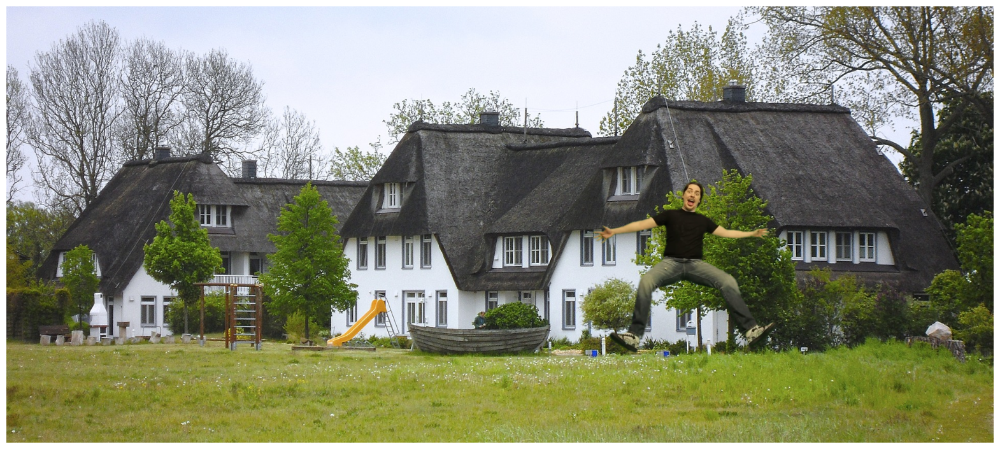

In [9]:
img_shfted_resized = resize_image(img_shifted, 40)
insert_image(img_background, img_shfted_resized)
show(img_background, (20, 20))


# 4- Crie função de rotação de imagens depois da aplicação da técnica de *chroma key*.



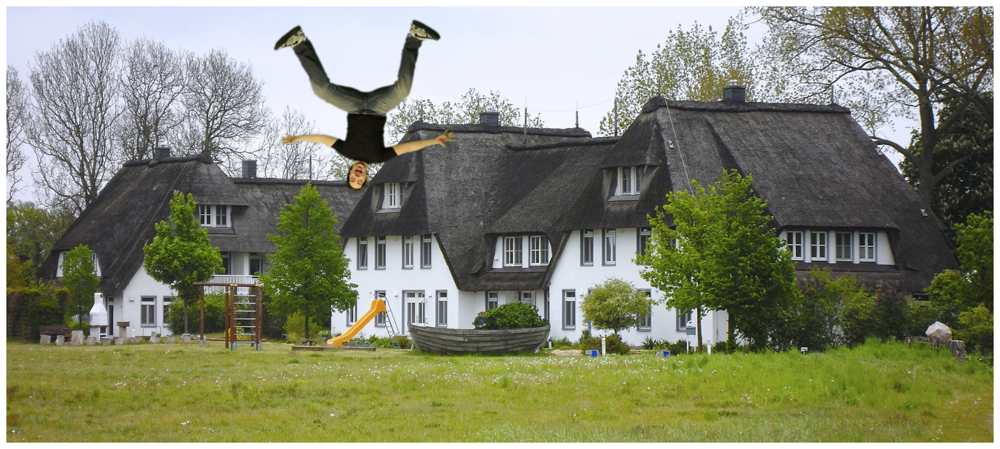

In [10]:
def rotate_image(image, angle):
    """
    Rotaciona a imagem pelo ângulo fornecido
    """

    # Tomando o centro da imagem como ponto de rotação
    image_center = tuple(np.array(image.shape[1::-1]) / 2)

    # Rotação da imagem
    rot_mat = cv2.getRotationMatrix2D(image_center, angle, 1.0)
    image_rotated = cv2.warpAffine(
        image, rot_mat, image.shape[1::-1], flags=cv2.INTER_LINEAR)

    return image_rotated


# Rotaciona a imagem em 180 graus (meia volta)
img_rotated = rotate_image(img_shfted_resized, 180)
img_background = open_image('./images/background.jpg')
insert_image(img_background, img_rotated)
show(img_background, (20, 20))


# 5- Adicione todas as imagens na imagem de *background*.

Image to insert is too bit to background


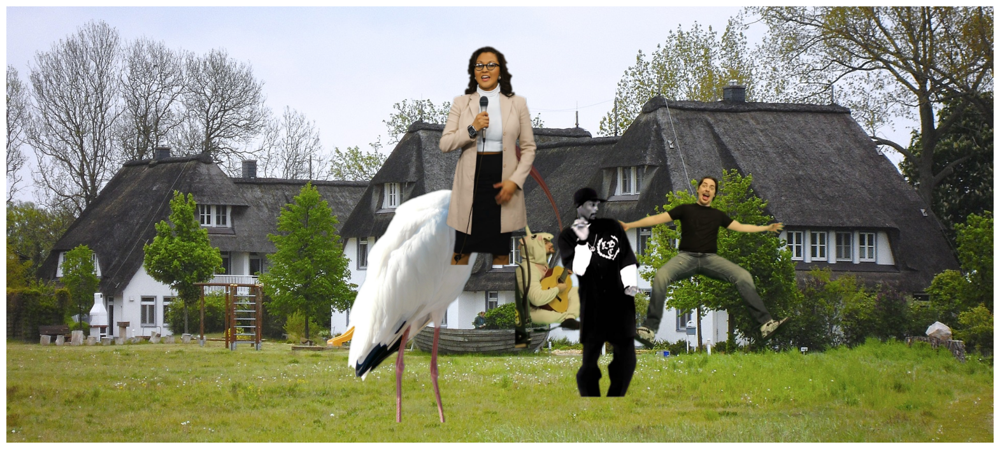

In [12]:
# add all images in background

img_background = open_image('./images/background.jpg')
img_chairman = open_image('./images/chairman.jpg')
img_crane = open_image('./images/crane.jpg')
img_girl = open_image('./images/girl.jpg')
img_reporter = open_image('./images/reporter.png')
img_snoop_dogg = open_image('./images/snoop-dogg.jpg')

img_chairman = green_to_transparency(img_chairman)
img_crane = green_to_transparency(img_crane)
img_girl = green_to_transparency(img_girl)
img_reporter = green_to_transparency(img_reporter)
img_snoop_dogg = green_to_transparency(img_snoop_dogg)

img_chairman = alpha_boundary(img_chairman)
img_crane = alpha_boundary(img_crane)
img_girl = alpha_boundary(img_girl)
img_reporter = alpha_boundary(img_reporter)
img_snoop_dogg = alpha_boundary(img_snoop_dogg)

img_chairman = resize_image(img_chairman, 40)
img_crane = resize_image(img_crane, 40)
img_girl = resize_image(img_girl, 40)
img_reporter = resize_image(img_reporter, 40)
img_snoop_dogg = resize_image(img_snoop_dogg, 40)

insert_image(img_background, img_chairman)
insert_image(img_background, img_crane)
insert_image(img_background, img_girl)
insert_image(img_background, img_reporter)
insert_image(img_background, img_snoop_dogg)

show(img_background, (20, 20))
